# CLIP-Adapter (Full Trainval Classification)

Dự án này triển khai thuật toán **CLIP-Adapter** để phân loại 37 giống chó/mèo từ tập dữ liệu **Oxford-IIIT Pet**.

### 1. Ý tưởng cốt lõi của CLIP-Adapter
* **CLIP-Adapter** thêm một mạng thần kinh đa tầng (MLP) nhỏ dạng Bottleneck để chuyển đổi các đặc trưng hình ảnh (visual features) trước khi thực hiện so sánh với đặc trưng văn bản.
* **Residual Connection (Kết nối thặng dư):**
  $$f^* = \alpha \cdot \text{MLP}(f) + (1 - \alpha) \cdot f$$
  Trong đó:
  - $f$ là visual feature gốc trích xuất từ CLIP Vision Encoder.
  - $\text{MLP}(f) = W_2 (\text{ReLU}(W_1(f)))$ là đặc trưng được tinh chỉnh thông qua 2 lớp tuyến tính (Linear bottleneck).
  - $\alpha$ là hệ số pha trộn (thường đặt $\alpha = 0.2$).
* **Đóng băng CLIP:** Toàn bộ trọng số của CLIP Vision Encoder và Text Encoder đều được đóng băng. Chỉ có duy nhất các tham số $W_1$ và $W_2$ của Adapter là được cập nhật thông qua quá trình lan truyền ngược.

### 2. Thiết lập bài toán (Full Trainval Split)
* Toàn bộ tập dữ liệu **trainval** (3680 ảnh) được chia làm 2 phần:
  - **Train Set (90%):** Dùng làm tập huấn luyện.
  - **Validation Set (10%):** Dùng để tối ưu tham số và early stopping.
* **Test Set:** Toàn bộ 3,669 ảnh trong tập **test** để làm Query/Test set đánh giá.


In [1]:
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor
import PIL.Image
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Thiết lập thiết bị chạy tự động (MPS cho macOS, CUDA cho GPU, hoặc CPU)
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available():
        return torch.device("mps")
    else:
        return torch.device("cpu")

device = get_device()
print(f"Sử dụng thiết bị phần cứng: {device}")

# Hàm thiết lập seed để đảm bảo tính tái lập kết quả
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Sử dụng thiết bị phần cứng: mps


In [2]:
class_names = [
    'Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 
    'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 
    'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 
    'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 
    'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 
    'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 
    'Wheaten Terrier', 'Yorkshire Terrier'
]

class_to_species = {
    # Cats
    'Abyssinian': 'cat', 'Bengal': 'cat', 'Birman': 'cat', 'Bombay': 'cat',
    'British Shorthair': 'cat', 'Egyptian Mau': 'cat', 'Maine Coon': 'cat',
    'Persian': 'cat', 'Ragdoll': 'cat', 'Russian Blue': 'cat', 'Siamese': 'cat',
    'Sphynx': 'cat',
    # Dogs
    'American Bulldog': 'dog', 'American Pit Bull Terrier': 'dog', 'Basset Hound': 'dog',
    'Beagle': 'dog', 'Boxer': 'dog', 'Chihuahua': 'dog', 'English Cocker Spaniel': 'dog', 
    'English Setter': 'dog', 'German Shorthaired': 'dog', 'Great Pyrenees': 'dog',
    'Havanese': 'dog', 'Japanese Chin': 'dog', 'Keeshond': 'dog', 'Leonberger': 'dog',
    'Miniature Pinscher': 'dog', 'Newfoundland': 'dog', 'Pomeranian': 'dog', 'Pug': 'dog',
    'Saint Bernard': 'dog', 'Samoyed': 'dog', 'Scottish Terrier': 'dog', 'Shiba Inu': 'dog',
    'Staffordshire Bull Terrier': 'dog', 'Wheaten Terrier': 'dog', 'Yorkshire Terrier': 'dog',
}


In [3]:
print("Tải CLIP Model và Processor...")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model.eval()

# Thiết lập đường dẫn load cache đặc trưng hình ảnh (Sử dụng đường dẫn tương đối ../../dataset)
trainval_features_path = "../../dataset/trainval_features.pt"
trainval_labels_path = "../../dataset/trainval_labels.pt"
test_features_path = "../../dataset/test_features.pt"
test_labels_path = "../../dataset/test_labels.pt"

# Nạp đặc trưng hình ảnh
if (os.path.exists(trainval_features_path) and os.path.exists(trainval_labels_path) and
    os.path.exists(test_features_path) and os.path.exists(test_labels_path)):
    print("Nạp các đặc trưng hình ảnh đã được cache thành công!")
    trainval_features = torch.load(trainval_features_path)
    trainval_labels = torch.load(trainval_labels_path)
    test_features = torch.load(test_features_path)
    test_labels = torch.load(test_labels_path)
    print(f"Kích thước trainval: {trainval_features.shape}")
    print(f"Kích thước test: {test_features.shape}")
else:
    raise FileNotFoundError("Không tìm thấy các file đặc trưng cache trong thư mục dataset/! Vui lòng chạy file extract_features.py trước.")


Tải CLIP Model và Processor...
Nạp các đặc trưng hình ảnh đã được cache thành công!
Kích thước trainval: torch.Size([3680, 512])
Kích thước test: torch.Size([3669, 512])


In [4]:
# Trích xuất và chuẩn hoá L2 đặc trưng của nhãn văn bản
prompts_enriched = [f"Picture of a pet with breed: {c}, which is a type of {class_to_species.get(c)}" for c in class_names]
with torch.no_grad():
    inputs_enriched = processor(text=prompts_enriched, return_tensors="pt", padding=True).to(device)
    text_features_enriched = model.get_text_features(**inputs_enriched)
    text_features_enriched = text_features_enriched / text_features_enriched.norm(dim=-1, keepdim=True)

print("Kích thước đặc trưng văn bản prompt enriched:", text_features_enriched.shape)


Kích thước đặc trưng văn bản prompt enriched: torch.Size([37, 512])


In [5]:
# Hàm phân chia trainval thành 90% train và 10% validation theo phân tầng (stratified)
def get_train_val_split(features, labels, train_ratio=0.9, seed=42):
    set_seed(seed)
    num_classes = 37
    train_idx = []
    val_idx = []
    
    for c in range(num_classes):
        class_indices = (labels == c).nonzero(as_tuple=True)[0]
        shuffled = class_indices[torch.randperm(len(class_indices))]
        
        split_point = int(len(class_indices) * train_ratio)
        train_idx.append(shuffled[:split_point])
        val_idx.append(shuffled[split_point:])
        
    train_idx = torch.cat(train_idx)
    val_idx = torch.cat(val_idx)
    
    return features[train_idx], labels[train_idx], features[val_idx], labels[val_idx]

train_features, train_labels, val_features, val_labels = get_train_val_split(
    trainval_features, trainval_labels, train_ratio=0.9, seed=42
)
print("Kích thước tập Train (90%):", train_features.shape)
print("Kích thước tập Validation (10%):", val_features.shape)


Kích thước tập Train (90%): torch.Size([3310, 512])
Kích thước tập Validation (10%): torch.Size([370, 512])


In [6]:
# Đánh giá độ chính xác Zero-Shot baseline
def evaluate_zero_shot(test_feats, test_lbls, text_feats):
    sim = test_feats.to(device) @ text_feats.to(device).t()
    preds = sim.argmax(dim=-1)
    acc = (preds == test_lbls.to(device)).float().mean().item()
    return acc * 100

acc_zs_enriched = evaluate_zero_shot(test_features, test_labels, text_features_enriched)
print(f"Độ chính xác Zero-Shot (Prompt Engineering): {acc_zs_enriched:.2f}%")


Độ chính xác Zero-Shot (Prompt Engineering): 88.44%


In [7]:
# Định nghĩa kiến trúc CLIP-Adapter
class CLIPAdapter(nn.Module):
    def __init__(self, input_dim=512, bottleneck_dim=64, alpha=0.2):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, bottleneck_dim),
            nn.ReLU(),
            nn.Linear(bottleneck_dim, input_dim)
        )
        self.alpha = alpha
        
        # Khởi tạo trọng số Linear cuối rất nhỏ
        nn.init.constant_(self.mlp[2].weight, 0.0)
        nn.init.constant_(self.mlp[2].bias, 0.0)
        
    def forward(self, x):
        # x: (Batch, 512)
        # Residual connection
        x_adapted = self.alpha * self.mlp(x) + (1.0 - self.alpha) * x
        # L2 Normalize
        x_adapted = x_adapted / x_adapted.norm(dim=-1, keepdim=True)
        return x_adapted

class AdapterClassifier(nn.Module):
    def __init__(self, adapter, text_features):
        super().__init__()
        self.adapter = adapter
        self.register_buffer("text_features", text_features.clone())
        
    def forward(self, x):
        x_adapted = self.adapter(x)
        logits = x_adapted @ self.text_features.t()
        return logits


In [8]:
# Hàm huấn luyện CLIP-Adapter
def train_clip_adapter(support_feats, support_lbls, val_feats, val_lbls, text_feats, epochs=50, lr=0.001):
    adapter = CLIPAdapter(input_dim=512, bottleneck_dim=64, alpha=0.2).to(device)
    model_adapter = AdapterClassifier(adapter, text_feats).to(device)
    
    optimizer = torch.optim.AdamW(model_adapter.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    dataset = TensorDataset(support_feats, support_lbls)
    batch_size = min(256, len(support_feats))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    best_val_acc = 0.0
    best_weights = None
    
    for epoch in range(epochs):
        model_adapter.train()
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            
            optimizer.zero_grad()
            outputs = model_adapter(x_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            
        # Đánh giá trên tập Validation
        model_adapter.eval()
        with torch.no_grad():
            val_outputs = model_adapter(val_feats.to(device))
            val_preds = val_outputs.argmax(dim=-1)
            val_acc = (val_preds == val_lbls.to(device)).float().mean().item()
            
        # Early Stopping
        if val_acc >= best_val_acc:
            best_val_acc = val_acc
            best_weights = model_adapter.state_dict().copy()
            
    if best_weights is not None:
        model_adapter.load_state_dict(best_weights)
        
    return model_adapter


In [9]:
# Huấn luyện Adapter (Định cấu hình 100 epochs để tối ưu hiệu năng)
print("1. Huấn luyện CLIP-Adapter trên tập Train (90% trainval) và validate trên 10% val...")
model_adapter = train_clip_adapter(
    train_features, train_labels, val_features, val_labels, text_features_enriched, epochs=100, lr=0.001
)

print("\n2. Chạy đánh giá trên tập Test...")
model_adapter.eval()
with torch.no_grad():
    logits_test = model_adapter(test_features.to(device))
    preds_test = logits_test.argmax(dim=-1)
    acc_adapter = (preds_test == test_labels.to(device)).float().mean().item() * 100
print(f"-> Độ chính xác CLIP-Adapter: {acc_adapter:.2f}%")


1. Huấn luyện CLIP-Adapter trên tập Train (90% trainval) và validate trên 10% val...

2. Chạy đánh giá trên tập Test...
-> Độ chính xác CLIP-Adapter: 82.58%


TÓM TẮT ĐỘ CHÍNH XÁC PHÂN LOẠI:
--------------------------------------------------
CLIP Zero-Shot (Prompt Eng):     88.44%
CLIP-Adapter (Full Train):       82.58%
--------------------------------------------------


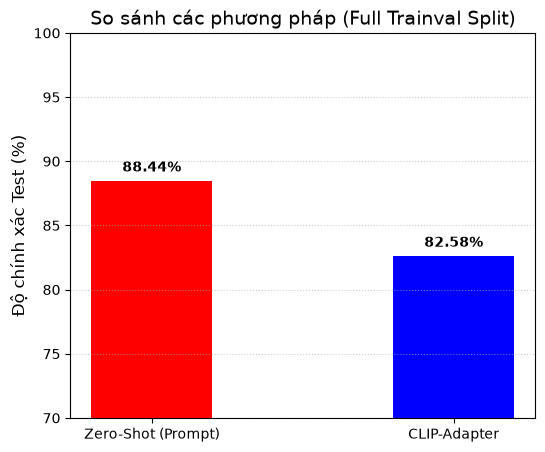

In [10]:
# Báo cáo kết quả bằng bảng
print("TÓM TẮT ĐỘ CHÍNH XÁC PHÂN LOẠI:")
print("-" * 50)
print(f"CLIP Zero-Shot (Prompt Eng):     {acc_zs_enriched:.2f}%")
print(f"CLIP-Adapter (Full Train):       {acc_adapter:.2f}%")
print("-" * 50)

# Trực quan hoá bằng biểu đồ cột
methods = ['Zero-Shot (Prompt)', 'CLIP-Adapter']
accuracies = [acc_zs_enriched, acc_adapter]

plt.figure(figsize=(6, 5))
bars = plt.bar(methods, accuracies, color=['red', 'blue'], width=0.4)
plt.title('So sánh các phương pháp (Full Trainval Split)', fontsize=14)
plt.ylabel('Độ chính xác Test (%)', fontsize=12)
plt.ylim(70, 100)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.savefig('clip_adapter_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


In [11]:
# Đo độ trễ suy diễn (Inference Latency)
print("Đang thực hiện đo đạc Latency...")

model_adapter.to(device)
latencies = []
for i in range(100):
    start = time.perf_counter()
    with torch.no_grad():
        test_img = test_features[i:i+1].to(device)
        logits = model_adapter(test_img)
        preds = logits.argmax(dim=-1)
    end = time.perf_counter()
    latencies.append((end - start) * 1000)

print(f"Thiết bị: {device}")
print(f"  Trung bình (Mean): {np.mean(latencies):.4f} ms")
print(f"  Phân vị p50 (Median): {np.percentile(latencies, 50):.4f} ms")
print(f"  Phân vị p95: {np.percentile(latencies, 95):.4f} ms")
print(f"  Phân vị p99: {np.percentile(latencies, 99):.4f} ms")

latencies_cpu = []
model_adapter_cpu = model_adapter.cpu()
test_features_cpu = test_features.cpu()
for i in range(100):
    start = time.perf_counter()
    with torch.no_grad():
        test_img = test_features_cpu[i:i+1]
        logits = model_adapter_cpu(test_img)
        preds = logits.argmax(dim=-1)
    end = time.perf_counter()
    latencies_cpu.append((end - start) * 1000)

print(f"Thiết bị: CPU")
print(f"  Trung bình (Mean): {np.mean(latencies_cpu):.4f} ms")
print(f"  Phân vị p50 (Median): {np.percentile(latencies_cpu, 50):.4f} ms")
print(f"  Phân vị p95: {np.percentile(latencies_cpu, 95):.4f} ms")
print(f"  Phân vị p99: {np.percentile(latencies_cpu, 99):.4f} ms")


Đang thực hiện đo đạc Latency...
Thiết bị: mps
  Trung bình (Mean): 3.2730 ms
  Phân vị p50 (Median): 0.3614 ms
  Phân vị p95: 0.4886 ms
  Phân vị p99: 3.9546 ms
Thiết bị: CPU
  Trung bình (Mean): 0.0286 ms
  Phân vị p50 (Median): 0.0266 ms
  Phân vị p95: 0.0328 ms
  Phân vị p99: 0.0461 ms


Tạo Ma Trận Nhầm Lẫn cho mô hình CLIP-Adapter...


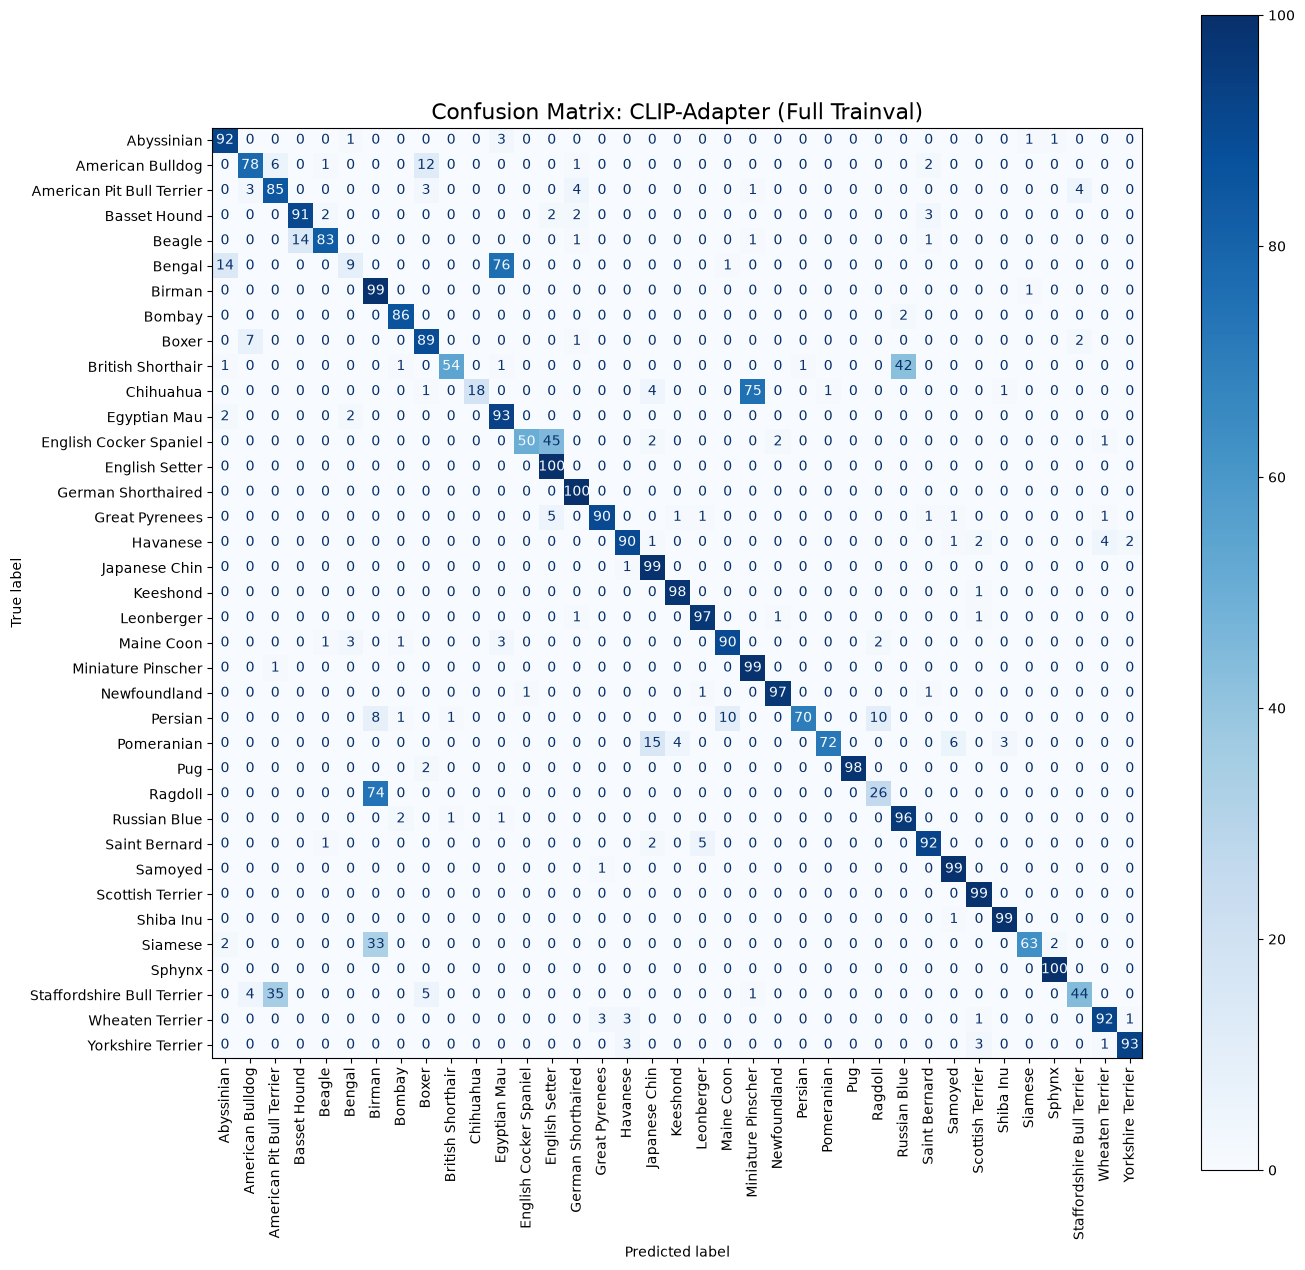

In [12]:
# Tạo ma trận nhầm lẫn (Confusion Matrix)
print("Tạo Ma Trận Nhầm Lẫn cho mô hình CLIP-Adapter...")
cm = confusion_matrix(test_labels.numpy(), preds_test.cpu().numpy())

fig, ax = plt.subplots(figsize=(15, 15))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation='vertical')
plt.title("Confusion Matrix: CLIP-Adapter (Full Trainval)", fontsize=16)
plt.savefig('confusion_matrix_adapter_16shot.png', bbox_inches='tight', dpi=300)
plt.show()


In [13]:
# Lưu kết quả
import json
os.makedirs("results", exist_ok=True)

summary_data = {
    "zs_enriched": acc_zs_enriched,
    "adapter_acc": acc_adapter,
    "latency_device": {
        "device": str(device),
        "mean": float(np.mean(latencies)),
        "p50": float(np.percentile(latencies, 50)),
        "p95": float(np.percentile(latencies, 95)),
        "p99": float(np.percentile(latencies, 99))
    }
}

with open("results/summary_results_adapter.json", "w") as f:
    json.dump(summary_data, f, indent=4)
    
print("Lưu file kết quả thành công tại results/summary_results_adapter.json!")


Lưu file kết quả thành công tại results/summary_results_adapter.json!
